# EDA del dataset Telco Customer Churn

Antes de entrenar cualquier modelo quiero entender los datos: cuántos son, si vienen limpios y qué tienen que ver con que un cliente se vaya o se quede.

## 1. Cargar los datos y ver el tamaño

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv("../data/Telco-Customer-Churn.csv")

print("Filas y columnas:", df.shape)
print("Tipos de datos:")
print(df.dtypes)
print("Primeras filas:")
df.head()

Filas y columnas: (7043, 21)
Tipos de datos:
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object
Primeras filas:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Casi todo son columnas de texto (servicios contratados, tipo de contrato, método de pago) y tres son numéricas de verdad: `tenure` (meses como cliente), `MonthlyCharges` y `TotalCharges`.

Pero hay algo raro: `TotalCharges` aparece como texto, cuando debería ser un número porque es dinero acumulado.

## 2. Nulos, duplicados y el problema de `TotalCharges`

In [2]:
print("Nulos en total:", df.isna().sum().sum())
print("Filas duplicadas:", df.duplicated().sum())
print("¿customerID es único?:", df["customerID"].is_unique)

Nulos en total: 0
Filas duplicadas: 0
¿customerID es único?: True


A simple vista todo está bien: cero nulos, cero duplicados y cada cliente aparece una sola vez. Pero eso no explica por qué `TotalCharges` es texto. Si intentamos convertirla a número, las celdas que no se puedan convertir se van a marcar como nulas:

In [3]:
total = pd.to_numeric(df["TotalCharges"], errors="coerce")   # lo que no sea número queda en NaN
raros = df[total.isna()]

print("Filas con TotalCharges que no es un número:", len(raros))
raros[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]].assign(
    TotalCharges=raros["TotalCharges"].map(repr)    # repr para ver qué hay realmente en la celda
)

Filas con TotalCharges que no es un número: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,' ',No
753,3115-CZMZD,0,20.25,' ',No
936,5709-LVOEQ,0,80.85,' ',No
1082,4367-NUYAO,0,25.75,' ',No
1340,1371-DWPAZ,0,56.05,' ',No
3331,7644-OMVMY,0,19.85,' ',No
3826,3213-VVOLG,0,25.35,' ',No
4380,2520-SGTTA,0,20.00,' ',No
5218,2923-ARZLG,0,19.70,' ',No
6670,4075-WKNIU,0,73.35,' ',No


Son 11 filas donde `TotalCharges` no está vacía como tal: tiene un espacio en blanco (`' '`). Por eso `isna()` no las contó como nulos y la columna quedó como texto.

Lo importante es que **las 11 tienen `tenure = 0`**, es decir, son clientes recién llegados que todavía no han recibido ninguna factura. Tiene sentido que no tengan total acumulado. Además ninguno se ha ido todavía (`Churn = No`).

Conclusión: no son datos dañados, es un caso normal de cliente nuevo. La estrategia que seguiremos es reemplazarlos por 0, porque eso es lo que han pagado hasta ahora. No tiene sentido eliminarlos (son clientes reales) ni rellenarlos con el promedio (eso diría que pagaron cientos de dólares sin haber sido facturados).

In [4]:
df["TotalCharges"] = total.fillna(0)

print("Tipo de TotalCharges ahora:", df["TotalCharges"].dtype)
print("Nulos restantes:", df.isna().sum().sum())

Tipo de TotalCharges ahora: float64
Nulos restantes: 0


## 3. La columna `customerID`

Antes de seguir me pregunto si `customerID` sirve para predecir algo. Ya vimos que es único para cada cliente; lo confirmo y miro cómo se ve:

In [5]:
print("IDs distintos:", df["customerID"].nunique(), "de", len(df), "filas")
df["customerID"].head()

IDs distintos: 7043 de 7043 filas


0    7590-VHVEG
1    5575-GNVDE
2    3668-QPYBK
3    7795-CFOCW
4    9237-HQITU
Name: customerID, dtype: str

Hay un ID distinto por cada fila, así que es solo una etiqueta para identificar al cliente. No dice nada sobre él: ni cuánto paga, ni qué servicios tiene, ni cuánto tiempo lleva.

Conclusión: no aporta información para predecir el abandono y hasta podría perjudicar. Como es distinto en cada fila, un modelo podría memorizarlo en lugar de aprender patrones reales (sobreajuste), y para un cliente nuevo ese código no significaría nada. Además, cuando despleguemos la API no tendría sentido pedirle al usuario ese dato.

Estrategia: lo eliminamos de las variables antes de entrenar. El archivo original no se toca, así que si más adelante hay que volver a un cliente en particular, el ID sigue ahí.

In [6]:
df = df.drop(columns="customerID")
print("Filas y columnas ahora:", df.shape)

Filas y columnas ahora: (7043, 20)


Quedan 20 columnas: las 19 variables que describen al cliente más `Churn`.

## 4. Variable objetivo: `Churn`

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Porcentaje que abandona: 26.5%


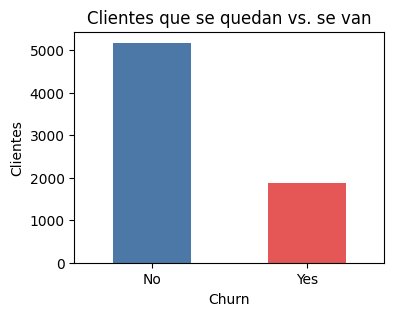

In [7]:
df["Churn_num"] = (df["Churn"] == "Yes").astype(int)    # 1 = se fue, 0 = se quedó

conteo = df["Churn"].value_counts()
print(conteo)
print()
print(f"Porcentaje que abandona: {df['Churn_num'].mean():.1%}")

conteo.plot(kind="bar", color=["#4C78A8", "#E45756"], rot=0, figsize=(4, 3))
plt.title("Clientes que se quedan vs. se van")
plt.ylabel("Clientes")
plt.show()

Más o menos 1 de cada 4 clientes se va (26,5 %). Hay desbalance, pero no extremo.

Esto cambia cómo vamos a evaluar el modelo: si uno predice "nadie se va" para todos, acierta el 73,5 % de las veces sin servir para nada. Por eso no vamos a quedarnos solo con el accuracy; vamos a mirar también el AUC, el recall y el F1 de la clase "se va". Y al dividir en train y test se debe usar `stratify` para que los dos conjuntos mantengan esa misma proporción.

## 5. Variables numéricas

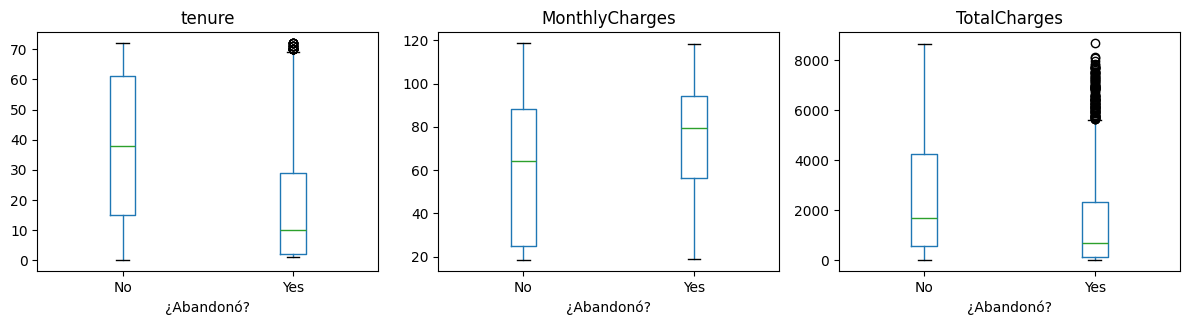

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,38.0,64.4,1679.5
Yes,10.0,79.6,703.6


In [8]:
numericas = ["tenure", "MonthlyCharges", "TotalCharges"]

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, col in zip(axes, numericas):
    df.boxplot(column=col, by="Churn", ax=ax, grid=False)
    ax.set_title(col)
    ax.set_xlabel("¿Abandonó?")
plt.suptitle("")
plt.tight_layout()
plt.show()

df.groupby("Churn")[numericas].median().round(1)

Comparando las medianas de quienes se quedan y quienes se van:

- **`tenure`:** la diferencia es enorme. Los que se van llevaban una mediana de 10 meses y los que se quedan, 38. Se van sobre todo los clientes nuevos.
- **`MonthlyCharges`:** los que se van pagan más por mes (mediana de 79,6 contra 64,4).
- **`TotalCharges`:** los que se van tienen menos total acumulado, pero esto es casi una consecuencia de lo primero: si llevan poco tiempo, han pagado poco en total.

Conclusión: la antigüedad es una variable clave. Como las tres numéricas están en escalas muy distintas (`tenure` va de 0 a 72 y `TotalCharges` hasta casi 8.700), vamos a estandarizarlas antes de entrenar.

## 6. Variables categóricas
Para cada categoría calculo qué porcentaje de esos clientes abandona. La línea punteada es la tasa global (26,5 %): las barras que la pasan son grupos de más riesgo.

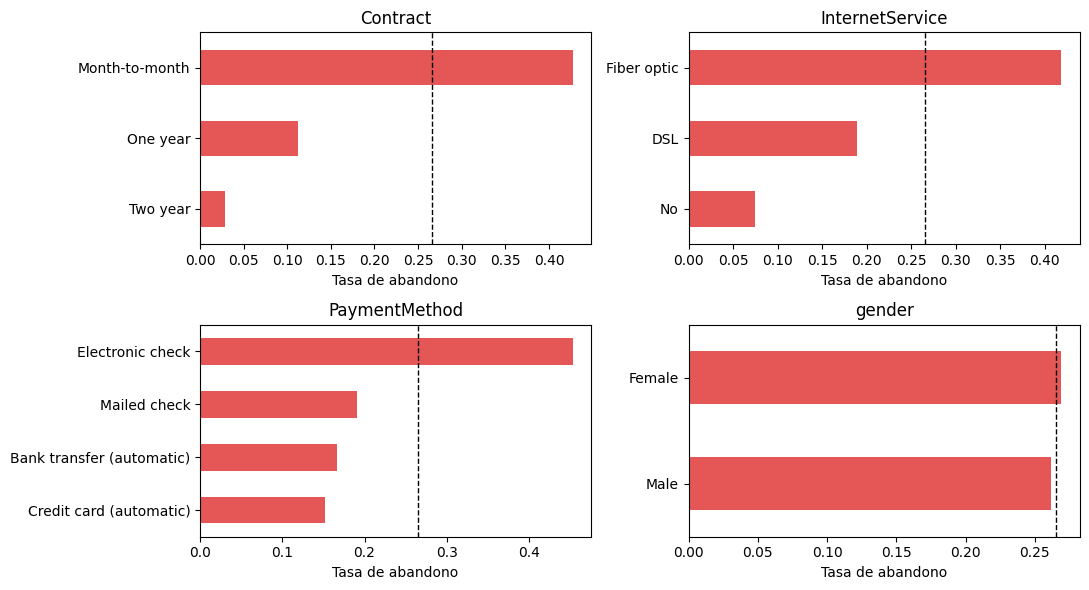

In [9]:
categoricas = ["Contract", "InternetService", "PaymentMethod", "gender"]
tasa_global = df["Churn_num"].mean()

fig, axes = plt.subplots(2, 2, figsize=(11, 6))
for ax, col in zip(axes.ravel(), categoricas):
    tasas = df.groupby(col)["Churn_num"].mean().sort_values()
    tasas.plot(kind="barh", ax=ax, color="#E45756")
    ax.axvline(tasa_global, color="black", linestyle="--", linewidth=1)
    ax.set_title(col)
    ax.set_xlabel("Tasa de abandono")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

Lo que se ve:

- **`Contract`:** es lo que más pesa. Con contrato mensual se va el 43 %; con contrato de un año, el 11 %; con dos años, apenas el 3 %.
- **`InternetService`:** los de fibra óptica abandonan mucho más (42 %) que los de DSL (19 %) o que quienes no tienen internet (7 %).
- **`PaymentMethod`:** pagar con cheque electrónico se asocia con un abandono del 45 %, contra 15-19 % en los otros métodos.
- **`gender`:** casi no hay diferencia (27 % mujeres, 26 % hombres), así que no parece aportar nada.

Hay que tener cuidado con interpretar esto como causa. Que el cheque electrónico se asocie con más abandono no quiere decir que cambiar el método de pago haga que el cliente se quede; probablemente esos clientes tienen otro perfil (por ejemplo, contrato mensual). Aquí solo estoy viendo asociaciones.

Estrategia: todas estas son categorías con pocos valores, así que las convertiremos con **one-hot encoding**, y a `gender` lo dejamos en el modelo de todas formas (no estorba y el modelo decide si la usa).

## 7. Resumen y qué sigue

| Lo que encontré | Qué voy a hacer |
|---|---|
| 11 clientes con `TotalCharges` en blanco, todos con `tenure = 0` (clientes nuevos) | Convertir a número y reemplazar por 0 |
| `customerID` es único por cliente y no describe nada de él | Eliminarlo antes de entrenar |
| El 26,5 % abandona (desbalance moderado) | Usar AUC, recall y F1, y partir los datos con `stratify` |
| `tenure`, `MonthlyCharges` y `TotalCharges` están en escalas muy distintas | Estandarizarlas |
| Los que se van son clientes nuevos, con contrato mensual, fibra óptica y pago con cheque electrónico | Esperar que el modelo use sobre todo estas variables |
| Las categóricas tienen pocos valores | One-hot encoding |